In [1]:
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [2]:
train_data = pd.read_csv(r'D:\Downloads\DL Datasets\fashion-mnist_train.csv')
test_data = pd.read_csv(r'D:\Downloads\DL Datasets\fashion-mnist_test.csv')

In [3]:
X_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

In [4]:
X_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

In [5]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [7]:
model = Sequential([
    Dense(128, activation='relu', input_shape=(784,)),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

C:\Users\SAKSHI\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
model.compile(
    optimizer='sgd',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [10]:
history = model.fit(
    X_train, y_train,
    epochs=11,
    validation_data=(X_test, y_test)
)

Epoch 1/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.7487 - loss: 0.7650 - val_accuracy: 0.8024 - val_loss: 0.5559
Epoch 2/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8272 - loss: 0.4967 - val_accuracy: 0.8344 - val_loss: 0.4673
Epoch 3/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8423 - loss: 0.4508 - val_accuracy: 0.8308 - val_loss: 0.4614
Epoch 4/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.8516 - loss: 0.4225 - val_accuracy: 0.8551 - val_loss: 0.4183
Epoch 5/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8578 - loss: 0.4031 - val_accuracy: 0.8568 - val_loss: 0.4053
Epoch 6/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8638 - loss: 0.3872 - val_accuracy: 0.8617 - val_loss: 0.3950
Epoch 7/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8671 - loss: 0.3750 - val_accuracy: 0.8660 - val_loss: 0.3857
Epoch 8/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8714 - loss: 0.3641 

In [11]:
loss, accuracy = model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8765 - loss: 0.3520


In [13]:
print("Training and valiation loss: ", loss)
print("Training and validation accuracy: ", accuracy)

Training and valiation loss:  0.3519621193408966
Training and validation accuracy:  0.8765000104904175


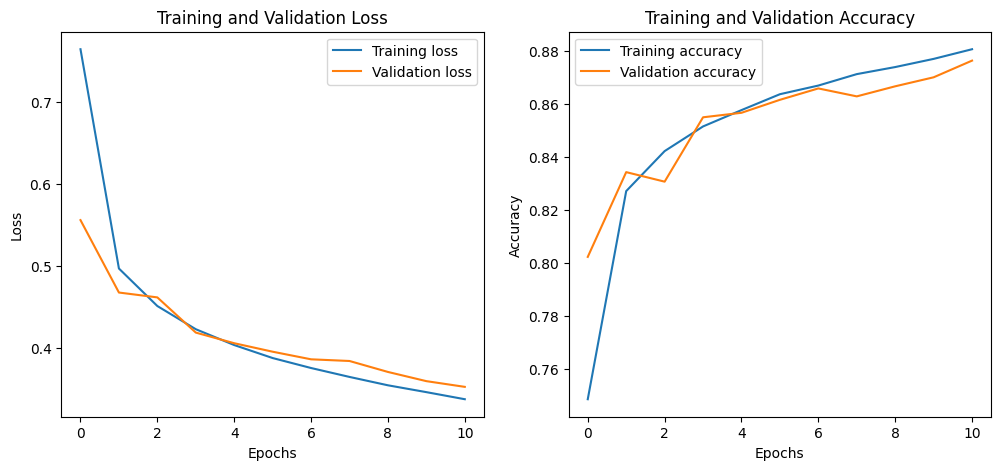

In [14]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


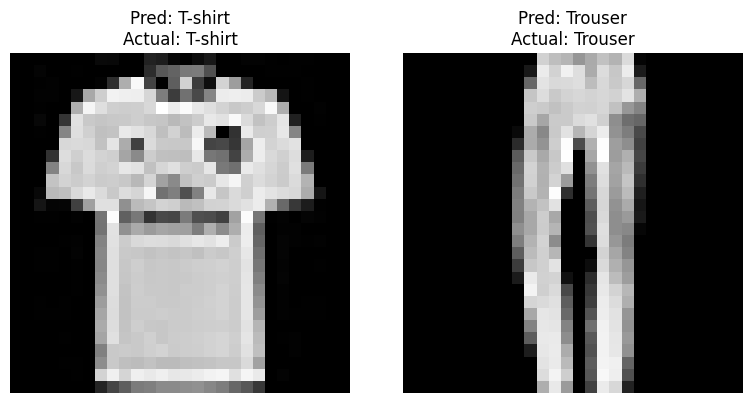

In [15]:
# Display 2 sample predictions
class_names = ['T-shirt', 'Trouser', 'Pullover', 'Dress',
               'Coat', 'Sandal', 'Shirt', 'Sneaker',
               'Bag', 'Ankle boot']

predictions = model.predict(X_test)
predicted_labels = predictions.argmax(axis=1)

plt.figure(figsize=(8, 4))

for i in range(2):
    plt.subplot(1, 2, i+1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title("Pred: " + class_names[predicted_labels[i]] +
              "\nActual: " + class_names[y_test[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()